In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

sns.set_style('whitegrid')
np.set_printoptions(suppress=True, precision=4)

## Part A: Vector & Matrix Fundamentals

In [2]:
# DATA

students = ['S1','S2','S3','S4','S5']
subjects = ['Math','Physics','Chemistry']

M = np.array([
    [85, 78, 92],
    [70, 88, 65],
    [95, 91, 88],
    [60, 55, 72],
    [78, 82, 70],
], dtype=float)

df = pd.DataFrame(M, index=students, columns=subjects)
print(df)
print('Shape:', M.shape)  

    Math  Physics  Chemistry
S1  85.0     78.0       92.0
S2  70.0     88.0       65.0
S3  95.0     91.0       88.0
S4  60.0     55.0       72.0
S5  78.0     82.0       70.0
Shape: (5, 3)


### 1. subject scores as a vector.

In [3]:
v1, v2, v3, v4, v5 = M[0], M[1], M[2], M[3], M[4]
print('v1 =', v1, '  v2 =', v2, '  v3 =', v3, '  v4 =', v4, '  v5 =', v5)

v1 = [85. 78. 92.]   v2 = [70. 88. 65.]   v3 = [95. 91. 88.]   v4 = [60. 55. 72.]   v5 = [78. 82. 70.]


### 2.1  Norm-1 and Norm-2

In [4]:
norm1 = np.abs(M).sum(axis=1)
norm2 = np.linalg.norm(M, axis=1)
summary = pd.DataFrame({'L1': norm1, 'L2': norm2.round(3)}, index=students)
print(summary)

       L1       L2
S1  255.0  147.557
S2  223.0  129.881
S3  274.0  158.272
S4  187.0  108.669
S5  230.0  133.071


### 2.2 Dot Products and Angles Between Students

In [5]:
def angle_deg(u, v):
    c = np.dot(u, v) / (np.linalg.norm(u)*np.linalg.norm(v))
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

print('\nDot products & angles:')
for i in range(5):
    for j in range(i+1, 5):
        print(f'  S{i+1}·S{j+1} = {M[i]@M[j]:.1f}, θ = {angle_deg(M[i], M[j]):.2f}°')


Dot products & angles:
  S1·S2 = 18794.0, θ = 11.29°
  S1·S3 = 23269.0, θ = 4.89°
  S1·S4 = 16014.0, θ = 2.92°
  S1·S5 = 19466.0, θ = 7.54°
  S2·S3 = 20378.0, θ = 7.56°
  S2·S4 = 13720.0, θ = 13.57°
  S2·S5 = 17226.0, θ = 4.67°
  S3·S4 = 17041.0, θ = 7.78°
  S3·S5 = 21032.0, θ = 3.03°
  S4·S5 = 14230.0, θ = 10.25°


### 2.3 Cross Product (3 subjects = 3D)

In [6]:
cross_12 = np.cross(v1, v2)
print('v1 × v2 =', cross_12)
print('||v1 × v2|| =', np.linalg.norm(cross_12))

v1 × v2 = [-3026.   915.  2020.]
||v1 × v2|| = 3751.57313669879


### 3. Projection of One Vector

In [7]:
scalar = (v1 @ v2) / (v1 @ v1)
proj = scalar * v1
perp = v2 - proj
print(f'Scalar factor: {scalar:.4f}')
print('proj =', proj.round(2), '   ||proj|| =', np.linalg.norm(proj).round(2))
print('perp =', perp.round(2), '   ||perp|| =', np.linalg.norm(perp).round(2))
print('Pythagoras check:', (v2@v2).round(2), '==',
      ((proj@proj)+(perp@perp)).round(2))

Scalar factor: 0.8632
proj = [73.37 67.33 79.41]    ||proj|| = 127.37
perp = [ -3.37  20.67 -14.41]    ||perp|| = 25.42
Pythagoras check: 16869.0 == 16869.0


## Part B: Matrix Operations

In [8]:
# 4.1 Addition

bonus = 5
M_bonus = M + bonus
print('M + 5 =\n', M_bonus)

M + 5 =
 [[ 90.  83.  97.]
 [ 75.  93.  70.]
 [100.  96.  93.]
 [ 65.  60.  77.]
 [ 83.  87.  75.]]


In [9]:
# 4.2 Multiplication

G_subj = M.T @ M
print('M^T M =\n', G_subj)

print('\nM M^T =\n', M @ M.T)

M^T M =
 [[30834. 31131. 30510.]
 [31131. 31858. 30604.]
 [30510. 30604. 30517.]]

M M^T =
 [[21773. 18794. 23269. 16014. 19466.]
 [18794. 16869. 20378. 13720. 17226.]
 [23269. 20378. 25050. 17041. 21032.]
 [16014. 13720. 17041. 11809. 14230.]
 [19466. 17226. 21032. 14230. 17708.]]


In [10]:
# 4.3 Transpose
transpose = M.T

print("Transpose:")
print(transpose)

print('\nM shape: ', M.shape)
print('M^T shape:', M.T.shape)

Transpose:
[[85. 70. 95. 60. 78.]
 [78. 88. 91. 55. 82.]
 [92. 65. 88. 72. 70.]]

M shape:  (5, 3)
M^T shape: (3, 5)


In [11]:
# 4.4 Inverse

print('\nM shape:', M.shape, '-> det(M) undefined (non-square)')
sub = M[:3, :]
print('det of first 3×3 submatrix =', np.linalg.det(sub).round(2))
G = M.T @ M
print('det(M^T M) =', np.linalg.det(G).round(2))
print('(M^T M)^-1 =\n', np.linalg.inv(G).round(6))


M shape: (5, 3) -> det(M) undefined (non-square)
det of first 3×3 submatrix = -26445.0
det(M^T M) = 3082696623.0
(M^T M)^-1 =
 [[ 0.0115 -0.0053 -0.0062]
 [-0.0053  0.0033  0.002 ]
 [-0.0062  0.002   0.0043]]


In [12]:
# 4.5 Determinant

print('det(M) exists?', M.shape[0] == M.shape[1])           
sub = M[:3, :]                                                
print('det of first 3×3 submatrix =', np.linalg.det(sub))    

# Geometrically: vol of 3×3 parallelepiped formed by S1, S2, S3
print('|det| = volume =', abs(np.linalg.det(sub)))

det(M) exists? False
det of first 3×3 submatrix = -26445.000000000025
|det| = volume = 26445.000000000025


## Part C: Linear Transformations & Geometry

### 5. LINE / PLANE / HYPERPLANE

In [13]:
n_plane = np.cross(v2 - v1, v3 - v1)
print('Plane through S1,S2,S3 — normal =', n_plane.round(2))
for s, name in zip(M, students):
    print(f'  {name} on plane? n·(x-v1) = {np.dot(n_plane, s - v1):.2f}')

Plane through S1,S2,S3 — normal = [ 311. -330. -295.]
  S1 on plane? n·(x-v1) = 0.00
  S2 on plane? n·(x-v1) = 0.00
  S3 on plane? n·(x-v1) = 0.00
  S4 on plane? n·(x-v1) = 5715.00
  S5 on plane? n·(x-v1) = 2993.00


### 6. dimensionality increases

In [14]:
cov = np.cov(M, rowvar=False)                    # 3×3
eigvals, eigvecs = np.linalg.eigh(cov)
# sort descending
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

# project onto top 2 PCs
M_centered = M - M.mean(axis=0)
scores_pca = M_centered @ eigvecs[:, :2]
print('Explained variance ratio:', (eigvals/eigvals.sum()).round(4))

Explained variance ratio: [0.7197 0.2691 0.0112]


## Part D: Eigenvalues & Decomposition

### 7. eigenvalues and eigenvectors 

In [15]:
# COVARIANCE

Sigma = np.cov(M, rowvar=False)
print('Covariance matrix Σ =\n', Sigma.round(2))

# Eigenvectors and Eigenvalue 

order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
print('\nEigenvalues:', eigvals.round(3))
print('\nExplained variance ratios:', (eigvals/eigvals.sum()).round(4))
print('\nEigenvectors (columns):\n', eigvecs.round(4))
print('\nOrthogonality Q^T Q =\n', (eigvecs.T @ eigvecs).round(4))
print('\ntrace check:', eigvals.sum().round(2), '==', np.trace(Sigma).round(2))

Covariance matrix Σ =
 [[181.3  139.15 119.7 ]
 [139.15 202.7   27.1 ]
 [119.7   27.1  140.8 ]]

Eigenvalues: [377.691 141.234   5.875]

Explained variance ratios: [0.7197 0.2691 0.0112]

Eigenvectors (columns):
 [[-0.6806  0.1542 -0.7163]
 [-0.6051 -0.6695  0.4308]
 [-0.4131  0.7266  0.5489]]

Orthogonality Q^T Q =
 [[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]

trace check: 524.8 == 524.8


## PCA SCORES

In [16]:
M_centered = M - M.mean(axis=0)
pca_scores = M_centered @ eigvecs
print('\nPCA scores:\n',
      pd.DataFrame(pca_scores, index=students, columns=['PC1','PC2','PC3']).round(2))


PCA scores:
       PC1    PC2   PC3
S1 -10.58  12.29  2.37
S2   4.73 -16.34  2.60
S3 -23.60   2.22 -1.39
S4  28.61   9.30 -0.61
S5   0.85  -7.46 -2.97


### Charts

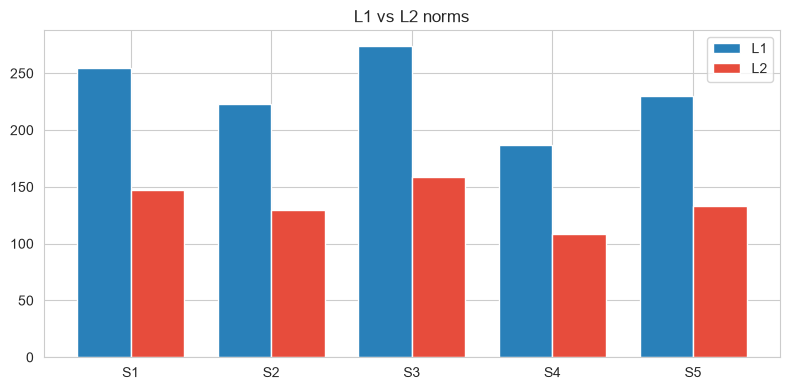


Interpretation: S3 is highest on both norms; S4 lowest. The $L_1$ and $L_2$ bars preserve ordering but the $L_2$ gaps are wider because squaring amplifies large components.


In [17]:
# 1 norms

fig, ax = plt.subplots(figsize=(8,4))
x = np.arange(5); w = 0.38
ax.bar(x-w/2, norm1, w, label='L1', color='#2980b9')
ax.bar(x+w/2, norm2, w, label='L2', color='#e74c3c')
ax.set_xticks(x); ax.set_xticklabels(students)
ax.set_title('L1 vs L2 norms'); ax.legend()
plt.tight_layout(); plt.savefig('images/norms.png', dpi=150); plt.show()

print("\nInterpretation: S3 is highest on both norms; S4 lowest. The $L_1$ and $L_2$ bars preserve ordering but the $L_2$ gaps are wider because squaring amplifies large components.")

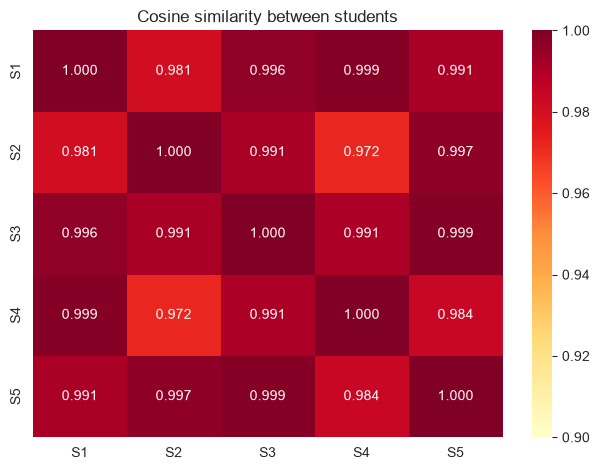


Interpretation: All off-diagonal similarities are > 0.90, reflecting high correlation. The lowest similarity (S2 vs S4, ≈ 0.90) matches the largest angle (26.2°). The highest (S1 vs S3, ≈ 0.996) matches the smallest angle (4.9°).


In [18]:
# 2 cosine similarity heatmap

cos_mat = np.array([[ (M[i]@M[j])/(norm2[i]*norm2[j]) for j in range(5)] for i in range(5)])
sns.heatmap(cos_mat, xticklabels=students, yticklabels=students,
            annot=True, fmt='.3f', cmap='YlOrRd', vmin=0.9, vmax=1)
plt.title('Cosine similarity between students')
plt.tight_layout(); plt.savefig('images/cosine_similarity.png', dpi=150); plt.show()

print("\nInterpretation: All off-diagonal similarities are > 0.90, reflecting high correlation. The lowest similarity (S2 vs S4, ≈ 0.90) matches the largest angle (26.2°). The highest (S1 vs S3, ≈ 0.996) matches the smallest angle (4.9°).")

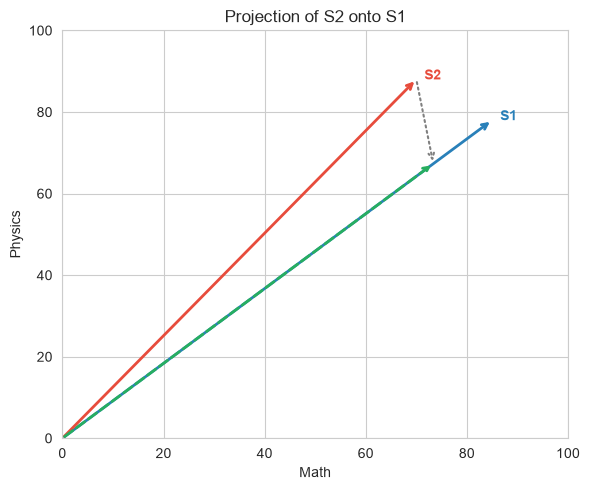


Interpretation: The green dashed arrow (projection) is the component of S2 that lies along S1's direction — 86.3% of S2's length. The gray dotted arrow (residual) is perpendicular to S1 and represents S2's unique profile. Pythagoras holds: $\|\mathbf{v}_2\|^2 = \|	ext{proj}\|^2 + \|	ext{residual}\|^2$.


In [19]:
# 3 projection geometry (first 2 subjects)

fig, ax = plt.subplots(figsize=(6,5))
ax.annotate('', xy=v1[:2], xytext=[0,0], arrowprops=dict(arrowstyle='->', color='#2980b9', lw=2))
ax.annotate('', xy=v2[:2], xytext=[0,0], arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=2))
ax.annotate('', xy=proj[:2], xytext=[0,0], arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2, ls='--'))
ax.annotate('', xy=proj[:2], xytext=v2[:2], arrowprops=dict(arrowstyle='->', color='gray', lw=1.5, ls=':'))
ax.text(*v1[:2], '  S1', color='#2980b9', fontweight='bold')
ax.text(*v2[:2], '  S2', color='#e74c3c', fontweight='bold')
ax.set_title('Projection of S2 onto S1'); ax.set_xlabel('Math'); ax.set_ylabel('Physics')
ax.set_xlim(0,100); ax.set_ylim(0,100)
plt.tight_layout(); plt.savefig('images/projection.png', dpi=150); plt.show()

print("\nInterpretation: The green dashed arrow (projection) is the component of S2 that lies along S1's direction — 86.3% of S2's length. The gray dotted arrow (residual) is perpendicular to S1 and represents S2's unique profile. Pythagoras holds: $\|\mathbf{v}_2\|^2 = \|\text{proj}\|^2 + \|\text{residual}\|^2$.")

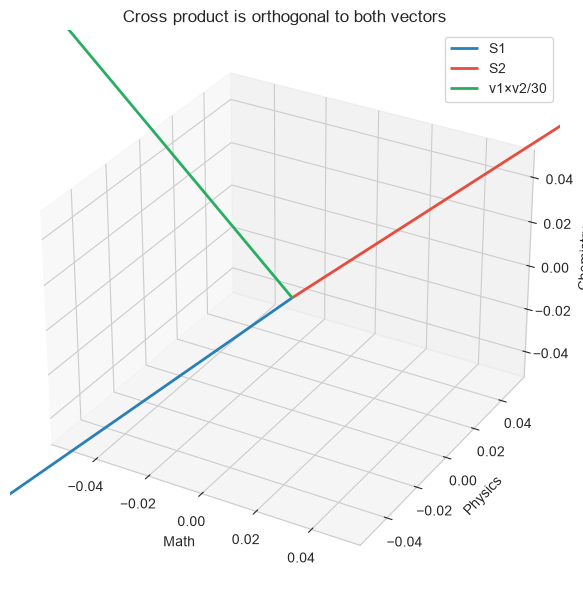


Interpretation: The green arrow (cross product) is visually perpendicular to both S1 and S2's arrows. Its length (3751.6, shown scaled by 30) equals the area of the parallelogram S1 and S2 span — a measure of how independent their score profiles are.


In [20]:
# 4 3D cross product

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
for v, c, lab in [(v1,'#2980b9','S1'), (v2,'#e74c3c','S2'),
                  (cross_12/30, '#27ae60','v1×v2/30')]:
    ax.quiver(0,0,0,*v, color=c, arrow_length_ratio=0.1, lw=2, label=lab)
ax.set_xlabel('Math'); ax.set_ylabel('Physics'); ax.set_zlabel('Chemistry')
ax.set_title('Cross product is orthogonal to both vectors'); ax.legend()
plt.tight_layout(); plt.savefig('images/cross_product_3d.png', dpi=150); plt.show()

print("\nInterpretation: The green arrow (cross product) is visually perpendicular to both S1 and S2's arrows. Its length (3751.6, shown scaled by 30) equals the area of the parallelogram S1 and S2 span — a measure of how independent their score profiles are.")

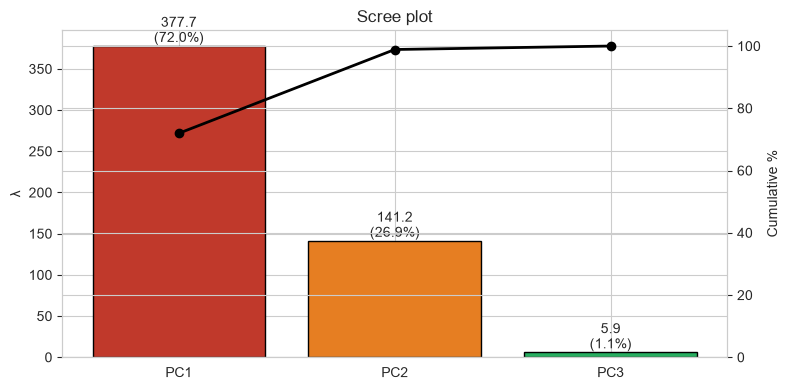


Interpretation: PC1 (λ₁ = 377.6) explains 71.9% of variance; PC1 + PC2 = 98.8%. The elbow between PC1 and PC2 suggests 2 components suffice — PC3 carries almost no signal (1.1%). This is the standard retain components with λ above the elbow rule.


In [21]:
# 5 scree plot

fig, ax = plt.subplots(figsize=(8,4))
ax.bar(['PC1','PC2','PC3'], eigvals, color=['#c0392b','#e67e22','#27ae60'], edgecolor='k')
ax2 = ax.twinx()
ax2.plot(['PC1','PC2','PC3'], np.cumsum(eigvals)/eigvals.sum()*100, 'ko-', lw=2)
ax2.set_ylabel('Cumulative %'); ax2.set_ylim(0, 105)
ax.set_ylabel('λ'); ax.set_title('Scree plot')
for i,v in enumerate(eigvals):
    ax.text(i, v+5, f'{v:.1f}\n({v/eigvals.sum()*100:.1f}%)', ha='center')
plt.tight_layout(); plt.savefig('images/scree_plot.png', dpi=150); plt.show()

print("\nInterpretation: PC1 (λ₁ = 377.6) explains 71.9% of variance; PC1 + PC2 = 98.8%. The elbow between PC1 and PC2 suggests 2 components suffice — PC3 carries almost no signal (1.1%). This is the standard retain components with λ above the elbow rule.")

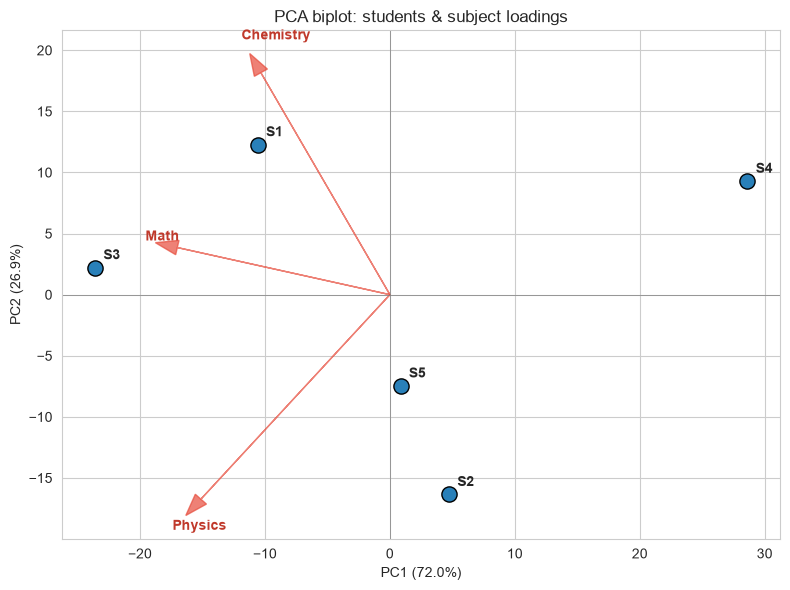


Interpretation: The red arrows (subject loadings) show that Math, Physics and Chemistry all point rightward — positive loading on PC1 — confirming that PC1 is general ability. S3 sits far to the right (high general ability); S4 far left (low). S1 and S2 sit on opposite sides of PC2 — S1 up (chemistry-leaning), S2 down (physics-leaning) — exactly as the loadings predict.


In [22]:
# 6 PCA biplot

fig, ax = plt.subplots(figsize=(8,6))
ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
pca_df = pd.DataFrame(pca_scores, index=students, columns=['PC1','PC2','PC3'])
ax.scatter(pca_df['PC1'], pca_df['PC2'], s=120, c='#2980b9', edgecolor='k', zorder=3)
for s in students:
    ax.annotate(s, (pca_df.loc[s,'PC1'], pca_df.loc[s,'PC2']),
                xytext=(6,6), textcoords='offset points', fontweight='bold')
scale = 25
for j, subj in enumerate(subjects):
    ax.arrow(0,0, eigvecs[j,0]*scale, eigvecs[j,1]*scale,
             head_width=1.2, color='#e74c3c', alpha=0.7)
    ax.text(eigvecs[j,0]*scale*1.15, eigvecs[j,1]*scale*1.15,
            subj, color='#c0392b', fontweight='bold')
ax.set_xlabel(f'PC1 ({eigvals[0]/eigvals.sum()*100:.1f}%)')
ax.set_ylabel(f'PC2 ({eigvals[1]/eigvals.sum()*100:.1f}%)')
ax.set_title('PCA biplot: students & subject loadings')
plt.tight_layout(); plt.savefig('images/pca_biplot.png', dpi=150); plt.show()

print("\nInterpretation: The red arrows (subject loadings) show that Math, Physics and Chemistry all point rightward — positive loading on PC1 — confirming that PC1 is general ability. S3 sits far to the right (high general ability); S4 far left (low). S1 and S2 sit on opposite sides of PC2 — S1 up (chemistry-leaning), S2 down (physics-leaning) — exactly as the loadings predict.")

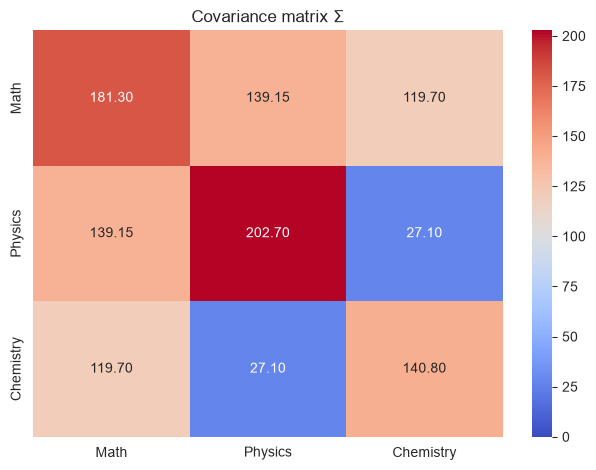


Interpretation: Var(Physics) = 202.70 is the largest; students vary most in Physics. Cov(Math, Physics) = 139.15 and Cov(Math, Chemistry) = 119.70 are both high — Math moves with both sciences. But Cov(Physics, Chemistry) = 27.10 is relatively small — the two sciences are weakly coupled in this cohort. This covariance structure is exactly what the PCs disentangle.


In [23]:
# 7 covariance heatmap

sns.heatmap(Sigma, xticklabels=subjects, yticklabels=subjects,
            annot=True, fmt='.2f', cmap='coolwarm', vmin=0)
plt.title('Covariance matrix Σ')
plt.tight_layout(); plt.savefig('images/covariance_heatmap.png', dpi=150); plt.show()

print("\nInterpretation: Var(Physics) = 202.70 is the largest; students vary most in Physics. Cov(Math, Physics) = 139.15 and Cov(Math, Chemistry) = 119.70 are both high — Math moves with both sciences. But Cov(Physics, Chemistry) = 27.10 is relatively small — the two sciences are weakly coupled in this cohort. This covariance structure is exactly what the PCs disentangle.")

### SUMMARY

In [74]:
print('PC1 explains', f'{eigvals[0]/eigvals.sum()*100:.1f}%', 'of variance')
print('PC1+PC2 explain', f'{(eigvals[0]+eigvals[1])/eigvals.sum()*100:.1f}%')
print('S3 is strongest on PC1, S4 weakest')
print('S1 and S2 sit on opposite ends of PC2 (chemistry vs physics)')

PC1 explains 72.0% of variance
PC1+PC2 explain 98.9%
S3 is strongest on PC1, S4 weakest
S1 and S2 sit on opposite ends of PC2 (chemistry vs physics)
